# ECommerce

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('events.csv')
df.head()

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2020-09-24 11:57:06 UTC,view,1996170,2144415922528452715,electronics.telephone,NaN,31.90,1515915625519388267,LJuJVLEjPT
1,2020-09-24 11:57:26 UTC,view,139905,2144415926932472027,computers.components.cooler,zalman,17.16,1515915625519380411,tdicluNnRY
2,2020-09-24 11:57:27 UTC,view,215454,2144415927158964449,NaN,NaN,9.81,1515915625513238515,4TMArHtXQy
3,2020-09-24 11:57:33 UTC,view,635807,2144415923107266682,computers.peripherals.printer,pantum,113.81,1515915625519014356,aGFYrNgC08
4,2020-09-24 11:57:36 UTC,view,3658723,2144415921169498184,NaN,cameronsino,15.87,1515915625510743344,aa4mmk0kwQ


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 885129 entries, 0 to 885128
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   event_time     885129 non-null  object 
 1   event_type     885129 non-null  object 
 2   product_id     885129 non-null  int64  
 3   category_id    885129 non-null  int64  
 4   category_code  648910 non-null  object 
 5   brand          672765 non-null  object 
 6   price          885129 non-null  float64
 7   user_id        885129 non-null  int64  
 8   user_session   884964 non-null  object 
dtypes: float64(1), int64(3), object(5)
memory usage: 60.8+ MB


In [4]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

print("\nEvent types:")
print(df['event_type'].value_counts())

print("\nUnique values:")
print(f"Users: {df['user_id'].nunique():,}")
print(f"Sessions: {df['user_session'].nunique():,}")
print(f"Products: {df['product_id'].nunique():,}")
print(f"Categories: {df['category_id'].nunique():,}")
print(f"Brands: {df['brand'].nunique():,}")

print("\nDuplicates:")
print(f"Duplicate rows: {df.duplicated().sum():,}")

Rows: 885,129
Columns: 9

Event types:
event_type
view        793748
cart         54035
purchase     37346
Name: count, dtype: int64

Unique values:
Users: 407,283
Sessions: 490,398
Products: 53,453
Categories: 718
Brands: 999

Duplicates:
Duplicate rows: 655


In [5]:
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_pct': df.isna().mean() * 100
})

missing.sort_values('missing_pct', ascending=False)

,missing_count,missing_pct
category_code,236219,26.687522
brand,212364,23.992435
user_session,165,0.018641
event_time,0,0.000000
event_type,0,0.000000
product_id,0,0.000000
category_id,0,0.000000
price,0,0.000000
user_id,0,0.000000


In [6]:
df['price'].describe()

count    885129.000000
mean        146.328713
std         296.807683
min           0.220000
25%          26.460000
50%          65.710000
75%         190.490000
max       64771.060000
Name: price, dtype: float64

In [7]:
print("Zero prices:", (df['price'] == 0).sum())
print("Negative prices:", (df['price'] < 0).sum())
print("Missing prices:", df['price'].isna().sum())

Zero prices: 0
Negative prices: 0
Missing prices: 0


In [8]:
df['event_datetime'] = pd.to_datetime(df['event_time'], utc=True)

df[['event_time', 'event_datetime']].head()

,event_time,event_datetime
0,2020-09-24 11:57:06 UTC,2020-09-24 11:57:06+00:00
1,2020-09-24 11:57:26 UTC,2020-09-24 11:57:26+00:00
2,2020-09-24 11:57:27 UTC,2020-09-24 11:57:27+00:00
3,2020-09-24 11:57:33 UTC,2020-09-24 11:57:33+00:00
4,2020-09-24 11:57:36 UTC,2020-09-24 11:57:36+00:00


In [9]:
print("Start:", df['event_datetime'].min())
print("End:", df['event_datetime'].max())

Start: 2020-09-24 11:57:06+00:00
End: 2021-02-28 23:59:09+00:00


In [10]:
print("Missing datetime:", df['event_datetime'].isna().sum())

Missing datetime: 0


In [11]:
df['event_type'].unique()

array(['view', 'cart', 'purchase'], dtype=object)

In [12]:
duplicates = df[df.duplicated(keep=False)].sort_values(
    ['user_id', 'event_datetime', 'product_id']
)

duplicates.head(20)

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,event_datetime
135997,2020-10-22 18:32:04 UTC,view,478724,2144415924491387038,computers.components.motherboard,asus,52.90,1515915625367766093,r5QKrUaDgr,2020-10-22 18:32:04+00:00
135998,2020-10-22 18:32:04 UTC,view,478724,2144415924491387038,computers.components.motherboard,asus,52.90,1515915625367766093,r5QKrUaDgr,2020-10-22 18:32:04+00:00
132075,2020-10-22 07:46:41 UTC,view,622757,2144415926848585945,NaN,NaN,102.16,1515915625373342675,obu3k5f27J,2020-10-22 07:46:41+00:00
132076,2020-10-22 07:46:41 UTC,view,622757,2144415926848585945,NaN,NaN,102.16,1515915625373342675,obu3k5f27J,2020-10-22 07:46:41+00:00
53101,2020-10-06 12:58:49 UTC,view,4099841,2144415922125799520,NaN,palmexx,56.67,1515915625388149041,ZlIip8HCO3,2020-10-06 12:58:49+00:00
53102,2020-10-06 12:58:49 UTC,view,4099841,2144415922125799520,NaN,palmexx,56.67,1515915625388149041,ZlIip8HCO3,2020-10-06 12:58:49+00:00
36875,2020-10-02 20:32:16 UTC,view,4079447,2144415926848585945,NaN,nzxt,158.17,1515915625424957684,7TcCWAT6S9,2020-10-02 20:32:16+00:00
36876,2020-10-02 20:32:16 UTC,view,4079447,2144415926848585945,NaN,nzxt,158.17,1515915625424957684,7TcCWAT6S9,2020-10-02 20:32:16+00:00
45272,2020-10-04 21:04:09 UTC,view,4078407,2144415926966026460,computers.components.cpu,amd,365.38,1515915625453727914,28821430-fbaf-4c08-8e7a-ac7fa3307b47,2020-10-04 21:04:09+00:00
45273,2020-10-04 21:04:09 UTC,view,4078407,2144415926966026460,computers.components.cpu,amd,365.38,1515915625453727914,28821430-fbaf-4c08-8e7a-ac7fa3307b47,2020-10-04 21:04:09+00:00


In [13]:
duplicates['event_type'].value_counts()

event_type
view        1272
cart           6
purchase       6
Name: count, dtype: int64

In [14]:
df.sort_values(['user_id', 'event_datetime']).head(20)

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,event_datetime
174670,2020-10-29 11:28:35 UTC,view,4101974,2144415939364389423,electronics.clocks,honor,76.48,1515915625353226922,7qejzWzHlR,2020-10-29 11:28:35+00:00
51155,2020-10-06 06:30:32 UTC,view,3506650,2144415935673401802,NaN,kester,28.98,1515915625353230067,ikPKHkuRhA,2020-10-06 06:30:32+00:00
242211,2020-11-09 08:52:51 UTC,view,124883,2144415924424278172,electronics.audio.acoustic,logitech,23.90,1515915625353230683,dn9FkZ11dA,2020-11-09 08:52:51+00:00
242297,2020-11-09 09:04:34 UTC,view,760044,2144415924424278172,electronics.audio.acoustic,dell,48.73,1515915625353230683,dn9FkZ11dA,2020-11-09 09:04:34+00:00
242335,2020-11-09 09:08:53 UTC,view,125325,2144415924424278172,electronics.audio.acoustic,logitech,23.90,1515915625353230683,dn9FkZ11dA,2020-11-09 09:08:53+00:00
242344,2020-11-09 09:10:59 UTC,view,461533,2144415924424278172,electronics.audio.acoustic,smartbuy,12.94,1515915625353230683,dn9FkZ11dA,2020-11-09 09:10:59+00:00
242379,2020-11-09 09:15:27 UTC,view,1399881,2144415924424278172,electronics.audio.acoustic,sven,28.52,1515915625353230683,dn9FkZ11dA,2020-11-09 09:15:27+00:00
242419,2020-11-09 09:22:00 UTC,view,1038457,2144415924424278172,electronics.audio.acoustic,bbk,16.84,1515915625353230683,dn9FkZ11dA,2020-11-09 09:22:00+00:00
242442,2020-11-09 09:25:34 UTC,view,886608,2144415924424278172,electronics.audio.acoustic,perfeo,13.32,1515915625353230683,dn9FkZ11dA,2020-11-09 09:25:34+00:00
242447,2020-11-09 09:26:38 UTC,view,3793158,2144415924424278172,electronics.audio.acoustic,canyon,10.03,1515915625353230683,dn9FkZ11dA,2020-11-09 09:26:38+00:00


In [15]:
df[df['user_session'].isna()]

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,event_datetime
2257,2020-09-24 23:47:04 UTC,view,1715896,2144415926731145430,computers.components.network_adapter,NaN,17.40,1515915625496120859,NaN,2020-09-24 23:47:04+00:00
6872,2020-09-26 05:14:39 UTC,view,3791351,2144415926966026460,computers.components.cpu,amd,204.29,1515915625519884058,NaN,2020-09-26 05:14:39+00:00
7898,2020-09-26 10:58:24 UTC,view,1785245,2144415925011480748,stationery.cartrige,canon,43.11,1515915625495954428,NaN,2020-09-26 10:58:24+00:00
11782,2020-09-27 11:59:41 UTC,view,1153724,2144415921169498184,NaN,zte,6.29,1515915625520228004,NaN,2020-09-27 11:59:41+00:00
24461,2020-09-30 07:31:01 UTC,view,1559260,2144415928845074703,computers.notebook,NaN,16.83,1515915625397674009,NaN,2020-09-30 07:31:01+00:00
...,...,...,...,...,...,...,...,...,...,...
796271,2021-02-13 10:49:04 UTC,view,4154439,2144415922587172973,electronics.telephone,NaN,12.22,1515915625584300834,NaN,2021-02-13 10:49:04+00:00
808622,2021-02-15 12:23:22 UTC,view,630863,2144415925011480748,stationery.cartrige,nv-print,17.62,1515915625605766062,NaN,2021-02-15 12:23:22+00:00
808625,2021-02-15 12:23:39 UTC,view,630863,2144415925011480748,stationery.cartrige,nv-print,17.62,1515915625605766062,NaN,2021-02-15 12:23:39+00:00
808626,2021-02-15 12:23:45 UTC,view,630863,2144415925011480748,stationery.cartrige,nv-print,17.62,1515915625605766062,NaN,2021-02-15 12:23:45+00:00


In [16]:
df[df['user_session'].isna()]['event_type'].value_counts()

event_type
view    159
cart      6
Name: count, dtype: int64

In [17]:
df['price'].quantile([0.5, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1])

0.500       65.71
0.750      190.49
0.900      397.48
0.950      486.81
0.990      889.98
0.995     1199.11
0.999     2570.73
1.000    64771.06
Name: price, dtype: float64

In [18]:
df.nlargest(20, 'price')[
    ['event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price']
]

,event_type,product_id,category_id,category_code,brand,price
51272,view,4170916,2144415922402623591,computers.peripherals.monitor,lg,64771.06
86316,view,4170916,2144415922402623591,computers.peripherals.monitor,lg,64771.06
418716,view,4170916,2144415922402623591,computers.peripherals.monitor,lg,64771.06
627562,view,4170916,2144415922402623591,computers.peripherals.monitor,lg,64771.06
298701,view,4078837,2144415927049912542,electronics.video.tv,samsung,42590.13
324573,view,4078837,2144415927049912542,electronics.video.tv,samsung,42590.13
395298,view,4078837,2144415927049912542,electronics.video.tv,samsung,42590.13
866584,view,4078837,2144415927049912542,electronics.video.tv,samsung,42590.13
13638,view,4078834,2144415927049912542,electronics.video.tv,samsung,27775.87
20028,view,4078834,2144415927049912542,electronics.video.tv,samsung,27775.87


In [19]:
top_priced_items = (
    df.groupby('product_id')
      .agg(
          category_code=('category_code', 'first'),
          brand=('brand', 'first'),
          max_price=('price', 'max'),
          views=('event_type', lambda s: (s == 'view').sum()),
          carts=('event_type', lambda s: (s == 'cart').sum()),
          purchases=('event_type', lambda s: (s == 'purchase').sum()),
      )
      .sort_values('max_price', ascending=False)
      .head(10)
)

print(f"99.9th percentile price: ${df['price'].quantile(0.999):,.0f}")
print(f"Max price in purchases:  ${df.loc[df['event_type']=='purchase', 'price'].max():,.0f}")
top_priced_items

99.9th percentile price: $2,571
Max price in purchases:  $3,718


,category_code,brand,max_price,views,carts,purchases
product_id,,,,,,
4170916,computers.peripherals.monitor,lg,64771.06,4,0,0
4078837,electronics.video.tv,samsung,42590.13,4,0,0
4078834,electronics.video.tv,samsung,27775.87,5,0,0
3830190,None,dell,26985.35,2,0,0
4101181,computers.peripherals.printer,None,26909.62,1,0,0
3830191,None,dell,23242.11,3,0,0
3790935,None,dell,14233.22,1,0,0
4078835,electronics.video.tv,lg,13627.02,3,0,0
1633600,computers.peripherals.monitor,philips,12601.57,2,0,0


In [20]:
df = df.drop_duplicates().copy()

print(f"Rows after deduplication: {len(df):,}")
print(f"Duplicates remaining: {df.duplicated().sum():,}")

Rows after deduplication: 884,474
Duplicates remaining: 0


In [21]:
uncat_events_pct = df['category_code'].isna().mean()

has_category = df.groupby('product_id')['category_code'].apply(lambda s: s.notna().any())
uncat_products_pct = 1 - has_category.mean()

print(f"No category: {uncat_events_pct:.1%} of events, {uncat_products_pct:.1%} of products")

No category: 26.7% of events, 35.3% of products


In [22]:
df_sessions = df.dropna(subset=['user_session']).copy()

In [23]:
df['category_code'] = df['category_code'].fillna('Unknown')
df['brand'] = df['brand'].fillna('Unknown')

In [24]:
df['event_date'] = df['event_datetime'].dt.date
df['event_month'] = df['event_datetime'].dt.to_period('M').astype(str)
df['event_week'] = df['event_datetime'].dt.isocalendar().week
df['event_day'] = df['event_datetime'].dt.day
df['event_hour'] = df['event_datetime'].dt.hour
df['day_of_week'] = df['event_datetime'].dt.day_name()

/var/folders/gv/gmp52n5x5zj2ybgm_gblbt1w0000gn/T/ipykernel_66650/3219699847.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['event_month'] = df['event_datetime'].dt.to_period('M').astype(str)


In [25]:
df[
    [
        'event_datetime',
        'event_date',
        'event_month',
        'event_week',
        'event_day',
        'event_hour',
        'day_of_week'
    ]
].head()

,event_datetime,event_date,event_month,event_week,event_day,event_hour,day_of_week
0,2020-09-24 11:57:06+00:00,2020-09-24,2020-09,39,24,11,Thursday
1,2020-09-24 11:57:26+00:00,2020-09-24,2020-09,39,24,11,Thursday
2,2020-09-24 11:57:27+00:00,2020-09-24,2020-09,39,24,11,Thursday
3,2020-09-24 11:57:33+00:00,2020-09-24,2020-09,39,24,11,Thursday
4,2020-09-24 11:57:36+00:00,2020-09-24,2020-09,39,24,11,Thursday


In [26]:
print(f"Rows: {len(df):,}")
print(f"Start: {df['event_datetime'].min()}")
print(f"End: {df['event_datetime'].max()}")
print(f"Users: {df['user_id'].nunique():,}")
print(f"Sessions: {df['user_session'].nunique():,}")

Rows: 884,474
Start: 2020-09-24 11:57:06+00:00
End: 2021-02-28 23:59:09+00:00
Users: 407,283
Sessions: 490,398


In [27]:
df_sessions = df.dropna(subset=['user_session']).copy()

print(f"All events: {len(df):,}")
print(f"Events with session: {len(df_sessions):,}")
print(f"Events without session: {df['user_session'].isna().sum():,}")

All events: 884,474
Events with session: 884,312
Events without session: 162


In [28]:
df_sessions['event_type'].value_counts()

event_type
view        792943
cart         54026
purchase     37343
Name: count, dtype: int64

In [29]:
user_funnel = (
    df.groupby('event_type')['user_id']
      .nunique()
      .reindex(['view', 'cart', 'purchase'])
)

user_funnel

event_type
view        406863
cart         36952
purchase     21304
Name: user_id, dtype: int64

In [30]:
user_view_to_cart = user_funnel['cart'] / user_funnel['view']
user_cart_to_purchase = user_funnel['purchase'] / user_funnel['cart']
user_view_to_purchase = user_funnel['purchase'] / user_funnel['view']

print(f"View → Cart: {user_view_to_cart:.2%}")
print(f"Cart → Purchase: {user_cart_to_purchase:.2%}")
print(f"View → Purchase: {user_view_to_purchase:.2%}")

View → Cart: 9.08%
Cart → Purchase: 57.65%
View → Purchase: 5.24%


In [31]:
view_users = set(df.loc[df['event_type'] == 'view', 'user_id'])
cart_users = set(df.loc[df['event_type'] == 'cart', 'user_id'])
purchase_users = set(df.loc[df['event_type'] == 'purchase', 'user_id'])

print("Cart users without view:", len(cart_users - view_users))
print("Purchase users without view:", len(purchase_users - view_users))
print("Purchase users without cart:", len(purchase_users - cart_users))

Cart users without view: 2
Purchase users without view: 420
Purchase users without cart: 1248


In [32]:
session_funnel = (
    df_sessions.groupby('event_type')['user_session']
               .nunique()
               .reindex(['view', 'cart', 'purchase'])
)

session_funnel

event_type
view        488360
cart         41270
purchase     24344
Name: user_session, dtype: int64

In [33]:
session_view_to_cart = session_funnel['cart'] / session_funnel['view']
session_cart_to_purchase = session_funnel['purchase'] / session_funnel['cart']
session_view_to_purchase = session_funnel['purchase'] / session_funnel['view']

print(f"View → Cart: {session_view_to_cart:.2%}")
print(f"Cart → Purchase: {session_cart_to_purchase:.2%}")
print(f"View → Purchase: {session_view_to_purchase:.2%}")

View → Cart: 8.45%
Cart → Purchase: 58.99%
View → Purchase: 4.98%


In [34]:
view_sessions = set(df_sessions.loc[df_sessions['event_type'] == 'view', 'user_session'])
cart_sessions = set(df_sessions.loc[df_sessions['event_type'] == 'cart', 'user_session'])
purchase_sessions = set(df_sessions.loc[df_sessions['event_type'] == 'purchase', 'user_session'])

print("Cart sessions without view:", len(cart_sessions - view_sessions))
print("Purchase sessions without view:", len(purchase_sessions - view_sessions))
print("Purchase sessions without cart:", len(purchase_sessions - cart_sessions))

Cart sessions without view: 14
Purchase sessions without view: 2032
Purchase sessions without cart: 3582


In [35]:
funnel_summary = pd.DataFrame({
    'stage': ['View', 'Cart', 'Purchase'],
    'users': [
        user_funnel['view'],
        user_funnel['cart'],
        user_funnel['purchase']
    ],
    'sessions': [
        session_funnel['view'],
        session_funnel['cart'],
        session_funnel['purchase']
    ]
})

funnel_summary

,stage,users,sessions
0,View,406863,488360
1,Cart,36952,41270
2,Purchase,21304,24344


In [36]:
funnel_summary['user_conversion_from_view'] = (
    funnel_summary['users'] / funnel_summary.loc[0, 'users']
)

funnel_summary['session_conversion_from_view'] = (
    funnel_summary['sessions'] / funnel_summary.loc[0, 'sessions']
)

funnel_summary

,stage,users,sessions,user_conversion_from_view,session_conversion_from_view
0,View,406863,488360,1.000000,1.000000
1,Cart,36952,41270,0.090822,0.084507
2,Purchase,21304,24344,0.052362,0.049848


In [37]:
df_sessions = df_sessions.sort_values(
    ['user_session', 'event_datetime']
).copy()

In [38]:
df_sessions['is_view'] = df_sessions['event_type'].eq('view')
df_sessions['is_cart'] = df_sessions['event_type'].eq('cart')
df_sessions['is_purchase'] = df_sessions['event_type'].eq('purchase')

In [39]:
df_sessions['view_before'] = (
    df_sessions.groupby('user_session')['is_view']
    .cumsum()
    .sub(df_sessions['is_view'].astype(int))
    .gt(0)
)

In [40]:
df_sessions['valid_cart'] = (
    df_sessions['is_cart'] &
    df_sessions['view_before']
)

In [41]:
df_sessions['cart_before'] = (
    df_sessions.groupby('user_session')['valid_cart']
    .cumsum()
    .sub(df_sessions['valid_cart'].astype(int))
    .gt(0)
)

In [42]:
df_sessions['valid_purchase'] = (
    df_sessions['is_purchase'] &
    df_sessions['view_before'] &
    df_sessions['cart_before']
)

In [43]:
strict_funnel = pd.Series({
    'View': df_sessions.loc[
        df_sessions['is_view'], 'user_session'
    ].nunique(),

    'Cart': df_sessions.loc[
        df_sessions['valid_cart'], 'user_session'
    ].nunique(),

    'Purchase': df_sessions.loc[
        df_sessions['valid_purchase'], 'user_session'
    ].nunique()
})

strict_funnel

View        488360
Cart         41225
Purchase     20698
dtype: int64

# Вывод
В результате анализа получена следующая воронка:

488 360 сессий содержали просмотр товара;
41 225 сессий дошли от просмотра до добавления товара в корзину;
20 698 сессий прошли последовательность View → Cart → Purchase.
Конверсия View → Cart составила 8,44%.

Конверсия Cart → Purchase составила 50,21%.

Итоговая конверсия View → Purchase составила 4,24%.

# Основной вывод

Наибольший drop-off происходит на этапе View → Cart.

При этом после добавления товара в корзину около половины соответствующих сессий завершаются покупкой.

Это позволяет предположить, что основной потенциал улучшения воронки находится не столько на этапе оформления покупки, сколько раньше — на этапе перехода от интереса к товару к намерению его приобрести.

Возможные направления для дальнейшего исследования:

цена;
качество карточки товара;
информация о товаре;
отзывы и рейтинг;
условия доставки;
наличие товара;
промоакции.
Данные факторы являются гипотезами и требуют дополнительной проверки.

In [44]:
strict_view_to_cart = (
    strict_funnel['Cart'] /
    strict_funnel['View']
)

strict_cart_to_purchase = (
    strict_funnel['Purchase'] /
    strict_funnel['Cart']
)

strict_view_to_purchase = (
    strict_funnel['Purchase'] /
    strict_funnel['View']
)

print(f"View → Cart: {strict_view_to_cart:.2%}")
print(f"Cart → Purchase: {strict_cart_to_purchase:.2%}")
print(f"View → Purchase: {strict_view_to_purchase:.2%}")

View → Cart: 8.44%
Cart → Purchase: 50.21%
View → Purchase: 4.24%


In [45]:
purchase_without_cart = df_sessions[
    df_sessions['is_purchase'] &
    ~df_sessions['cart_before']
]

print(
    purchase_without_cart['user_session'].nunique()
)

3835


In [46]:
purchase_without_cart['event_type'].value_counts()

event_type
purchase    5218
Name: count, dtype: int64

In [47]:
purchase_sessions_without_cart = (
    df_sessions[
        df_sessions['is_purchase'] &
        ~df_sessions['cart_before']
    ]
    .groupby('user_session')
    .agg(
        events=('event_type', 'size'),
        first_event=('event_datetime', 'min'),
        last_event=('event_datetime', 'max'),
        purchases=('is_purchase', 'sum'),
        views=('is_view', 'sum'),
        carts=('is_cart', 'sum')
    )
)

purchase_sessions_without_cart.head(20)

,events,first_event,last_event,purchases,views,carts
user_session,,,,,,
005wDfXQrv,1,2020-11-06 04:40:50+00:00,2020-11-06 04:40:50+00:00,1,0,0
01lskqgAFz,1,2021-02-19 04:02:07+00:00,2021-02-19 04:02:07+00:00,1,0,0
02N2rUZOAe,1,2020-10-10 12:59:57+00:00,2020-10-10 12:59:57+00:00,1,0,0
06d3bOoSqW,1,2021-02-15 17:24:08+00:00,2021-02-15 17:24:08+00:00,1,0,0
06vthDebl0,1,2020-11-29 01:07:53+00:00,2020-11-29 01:07:53+00:00,1,0,0
07gRNvpfyQ,1,2020-12-26 16:51:03+00:00,2020-12-26 16:51:03+00:00,1,0,0
08suCcfQTi,1,2020-12-03 17:36:00+00:00,2020-12-03 17:36:00+00:00,1,0,0
0AxRBHYjov,1,2020-12-19 09:10:59+00:00,2020-12-19 09:10:59+00:00,1,0,0
0B36G01Fwq,1,2020-12-10 06:57:39+00:00,2020-12-10 06:57:39+00:00,1,0,0


In [48]:
direct_purchase_sessions = (
    df_sessions[
        df_sessions['is_purchase'] &
        ~df_sessions['cart_before']
    ]
    .groupby('user_session')
    .agg(
        events=('event_type', 'size'),
        views=('is_view', 'sum'),
        carts=('is_cart', 'sum'),
        purchases=('is_purchase', 'sum')
    )
)

direct_purchase_sessions['purchase_type'] = 'Purchase without cart'

direct_purchase_sessions.loc[
    direct_purchase_sessions['views'] > 0,
    'purchase_type'
] = 'View → Purchase'

direct_purchase_sessions.loc[
    (direct_purchase_sessions['views'] == 0) &
    (direct_purchase_sessions['carts'] == 0),
    'purchase_type'
] = 'Purchase only'

direct_purchase_sessions['purchase_type'].value_counts()

purchase_type
Purchase only    3835
Name: count, dtype: int64

In [49]:
direct_purchase_sessions.groupby('purchase_type').agg(
    sessions=('events', 'size'),
    avg_events=('events', 'mean'),
    avg_views=('views', 'mean')
).sort_values('sessions', ascending=False)

,sessions,avg_events,avg_views
purchase_type,,,
Purchase only,3835,1.360626,0.0


In [50]:
funnel_chart = pd.DataFrame({
    'stage': ['View', 'Cart', 'Purchase'],
    'sessions': [
        strict_funnel['View'],
        strict_funnel['Cart'],
        strict_funnel['Purchase']
    ]
})

funnel_chart['conversion_from_previous'] = [
    1,
    strict_funnel['Cart'] / strict_funnel['View'],
    strict_funnel['Purchase'] / strict_funnel['Cart']
]

funnel_chart['conversion_from_view'] = (
    funnel_chart['sessions'] / funnel_chart.loc[0, 'sessions']
)

funnel_chart

,stage,sessions,conversion_from_previous,conversion_from_view
0,View,488360,1.000000,1.000000
1,Cart,41225,0.084415,0.084415
2,Purchase,20698,0.502074,0.042383


In [51]:
direct_purchase_sessions.groupby('purchase_type').agg(
    sessions=('events', 'size'),
    avg_events=('events', 'mean'),
    avg_views=('views', 'mean')
).sort_values('sessions', ascending=False)

,sessions,avg_events,avg_views
purchase_type,,,
Purchase only,3835,1.360626,0.0


In [52]:
funnel_chart

,stage,sessions,conversion_from_previous,conversion_from_view
0,View,488360,1.000000,1.000000
1,Cart,41225,0.084415,0.084415
2,Purchase,20698,0.502074,0.042383


In [53]:
direct_purchase_sessions['purchase_type'].value_counts()

purchase_type
Purchase only    3835
Name: count, dtype: int64

In [54]:
category_df = df_sessions[df_sessions['category_code'] != 'Unknown'].copy()

print(f"Events with known category: {len(category_df):,}")
print(f"Categories: {category_df['category_code'].nunique():,}")

Events with known category: 648,311
Categories: 107


In [55]:
category_events = (
    category_df
    .groupby(['category_code', 'event_type'])
    .agg(
        events=('user_session', 'size'),
        sessions=('user_session', 'nunique'),
        users=('user_id', 'nunique')
    )
    .reset_index()
)

category_events.head()

,category_code,event_type,events,sessions,users
0,accessories.bag,cart,64,56,52
1,accessories.bag,purchase,56,38,33
2,accessories.bag,view,1942,1300,1165
3,accessories.briefcase,cart,2,2,2
4,accessories.briefcase,view,11,8,8


In [56]:
category_funnel = (
    category_df
    .groupby(['category_code', 'event_type'])['user_session']
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=['view', 'cart', 'purchase'], fill_value=0)
    .reset_index()
)

category_funnel.head()

event_type,category_code,view,cart,purchase
0,accessories.bag,1300,56,38
1,accessories.briefcase,8,2,0
2,apparel.glove,87,1,0
3,appliances.environment.air_heater,580,18,11
4,appliances.environment.fan,62,1,0


In [57]:
category_funnel['view_to_cart'] = (
    category_funnel['cart'] /
    category_funnel['view']
)

category_funnel['cart_to_purchase'] = (
    category_funnel['purchase'] /
    category_funnel['cart'].replace(0, pd.NA)
)

category_funnel['view_to_purchase'] = (
    category_funnel['purchase'] /
    category_funnel['view']
)

category_funnel.head()

event_type,category_code,view,cart,purchase,view_to_cart,cart_to_purchase,view_to_purchase
0,accessories.bag,1300,56,38,0.043077,0.678571,0.029231
1,accessories.briefcase,8,2,0,0.250000,0.0,0.000000
2,apparel.glove,87,1,0,0.011494,0.0,0.000000
3,appliances.environment.air_heater,580,18,11,0.031034,0.611111,0.018966
4,appliances.environment.fan,62,1,0,0.016129,0.0,0.000000


In [58]:
top_categories = (
    category_funnel
    .sort_values('view', ascending=False)
    .head(20)
)

top_categories

event_type,category_code,view,cart,purchase,view_to_cart,cart_to_purchase,view_to_purchase
88,electronics.telephone,50357,4527,2875,0.089898,0.635078,0.057092
46,computers.components.videocards,44083,9335,4737,0.211760,0.507445,0.107456
104,stationery.cartrige,24261,2346,1657,0.096698,0.706309,0.068299
58,computers.peripherals.printer,23473,2628,1733,0.111958,0.659437,0.073830
77,electronics.audio.acoustic,16208,986,561,0.060834,0.568966,0.034613
51,computers.notebook,15522,1362,957,0.087746,0.702643,0.061654
39,computers.components.cpu,12920,1874,840,0.145046,0.448239,0.065015
41,computers.components.motherboard,12471,1729,890,0.138642,0.514748,0.071366
90,electronics.video.tv,12264,519,248,0.042319,0.477842,0.020222
87,electronics.tablet,11586,928,585,0.080097,0.630388,0.050492


In [59]:
category_funnel_filtered = category_funnel[
    category_funnel['view'] >= 1000
].copy()

print(
    f"Categories before filter: {len(category_funnel):,}"
)

print(
    f"Categories after filter: {len(category_funnel_filtered):,}"
)

Categories before filter: 107
Categories after filter: 54


In [60]:
top_conversion_categories = (
    category_funnel_filtered
    .sort_values('view_to_cart', ascending=False)
    .head(15)
)

top_conversion_categories[
    [
        'category_code',
        'view',
        'cart',
        'purchase',
        'view_to_cart',
        'cart_to_purchase',
        'view_to_purchase'
    ]
]

event_type,category_code,view,cart,purchase,view_to_cart,cart_to_purchase,view_to_purchase
46,computers.components.videocards,44083,9335,4737,0.211760,0.507445,0.107456
52,computers.peripherals.camera,2532,514,351,0.203002,0.682879,0.138626
59,computers.peripherals.scanner,1069,181,106,0.169317,0.585635,0.099158
43,computers.components.power_supply,4437,655,342,0.147622,0.522137,0.077079
39,computers.components.cpu,12920,1874,840,0.145046,0.448239,0.065015
41,computers.components.motherboard,12471,1729,890,0.138642,0.514748,0.071366
48,computers.ebooks,1848,238,149,0.128788,0.62605,0.080628
40,computers.components.hdd,4802,618,316,0.128696,0.511327,0.065806
58,computers.peripherals.printer,23473,2628,1733,0.111958,0.659437,0.073830
104,stationery.cartrige,24261,2346,1657,0.096698,0.706309,0.068299


In [61]:
low_conversion_categories = (
    category_funnel_filtered
    .sort_values('view_to_cart', ascending=True)
    .head(15)
)

low_conversion_categories[
    [
        'category_code',
        'view',
        'cart',
        'purchase',
        'view_to_cart',
        'cart_to_purchase',
        'view_to_purchase'
    ]
]

event_type,category_code,view,cart,purchase,view_to_cart,cart_to_purchase,view_to_purchase
12,appliances.kitchen.juicer,1487,6,2,0.004035,0.333333,0.001345
9,appliances.kitchen.coffee_machine,2455,44,17,0.017923,0.386364,0.006925
73,country_yard.cultivator,1329,25,8,0.018811,0.32,0.006020
85,electronics.clocks,2659,51,24,0.019180,0.470588,0.009026
44,computers.components.sound_card,1113,26,11,0.023360,0.423077,0.009883
26,auto.accessories.alarm,1990,47,20,0.023618,0.425532,0.010050
15,appliances.kitchen.microwave,1627,44,18,0.027044,0.409091,0.011063
42,computers.components.network_adapter,1137,32,17,0.028144,0.53125,0.014952
11,appliances.kitchen.grill,2076,67,46,0.032274,0.686567,0.022158
45,computers.components.tv_tuner,1376,50,31,0.036337,0.62,0.022529


In [62]:
overall_view_to_cart = (
    category_funnel_filtered['cart'].sum() /
    category_funnel_filtered['view'].sum()
)

print(f"Overall View → Cart benchmark: {overall_view_to_cart:.2%}")

Overall View → Cart benchmark: 10.12%


In [63]:
category_funnel_filtered['expected_carts'] = (
    category_funnel_filtered['view'] *
    overall_view_to_cart
)

category_funnel_filtered['cart_gap'] = (
    category_funnel_filtered['expected_carts'] -
    category_funnel_filtered['cart']
)

In [64]:
opportunity_categories = (
    category_funnel_filtered
    .sort_values('cart_gap', ascending=False)
    .head(15)
)

opportunity_categories[
    [
        'category_code',
        'view',
        'cart',
        'view_to_cart',
        'expected_carts',
        'cart_gap'
    ]
]

event_type,category_code,view,cart,view_to_cart,expected_carts,cart_gap
90,electronics.video.tv,12264,519,0.042319,1240.803373,721.803373
77,electronics.audio.acoustic,16208,986,0.060834,1639.835378,653.835378
88,electronics.telephone,50357,4527,0.089898,5094.841444,567.841444
79,electronics.audio.headphone,5319,260,0.048881,538.146864,278.146864
34,auto.accessories.videoregister,4628,205,0.044296,468.235324,263.235324
87,electronics.tablet,11586,928,0.080097,1172.207101,244.207101
38,computers.components.cooler,5749,341,0.059315,581.651875,240.651875
85,electronics.clocks,2659,51,0.019180,269.022845,218.022845
51,computers.notebook,15522,1362,0.087746,1570.429710,208.429710
9,appliances.kitchen.coffee_machine,2455,44,0.017923,248.383258,204.383258


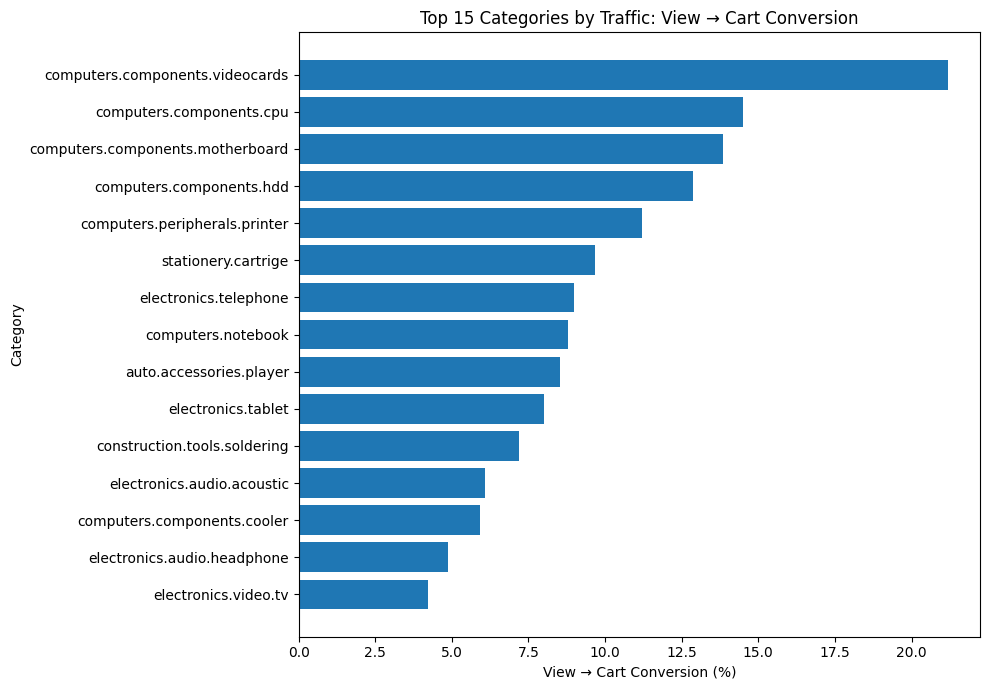

In [65]:
import matplotlib.pyplot as plt

plot_data = (
    category_funnel_filtered
    .sort_values('view', ascending=False)
    .head(15)
    .sort_values('view_to_cart')
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_data['category_code'],
    plot_data['view_to_cart'] * 100
)

plt.xlabel('View → Cart Conversion (%)')
plt.ylabel('Category')
plt.title('Top 15 Categories by Traffic: View → Cart Conversion')

plt.tight_layout()
plt.show()

In [66]:
price_bins = [0, 25, 50, 100, 200, 500, 1000, 2500, float('inf')]

price_labels = [
    '< $25',
    '$25–50',
    '$50–100',
    '$100–200',
    '$200–500',
    '$500–1K',
    '$1K–2.5K',
    '$2.5K+'
]

df_sessions['price_band'] = pd.cut(
    df_sessions['price'],
    bins=price_bins,
    labels=price_labels,
    include_lowest=True
)

df_sessions['price_band'].value_counts().sort_index()

price_band
< $25       210754
$25–50      156867
$50–100     171948
$100–200    131895
$200–500    172464
$500–1K      33935
$1K–2.5K      5454
$2.5K+         995
Name: count, dtype: int64

In [67]:
price_funnel = (
    df_sessions
    .groupby(['price_band', 'event_type'], observed=True)['user_session']
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=['view', 'cart', 'purchase'], fill_value=0)
    .reset_index()
)

price_funnel

event_type,price_band,view,cart,purchase
0,< $25,139367,9205,5947
1,$25–50,100981,7732,4995
2,$50–100,103532,7303,4206
3,$100–200,77855,6332,3604
4,$200–500,87241,11148,5655
5,$500–1K,19267,1989,1031
6,$1K–2.5K,4180,112,51
7,$2.5K+,790,22,7


In [68]:
price_funnel['view_to_cart'] = (
    price_funnel['cart'] /
    price_funnel['view']
)

price_funnel['cart_to_purchase'] = (
    price_funnel['purchase'] /
    price_funnel['cart'].replace(0, pd.NA)
)

price_funnel['view_to_purchase'] = (
    price_funnel['purchase'] /
    price_funnel['view']
)

price_funnel

event_type,price_band,view,cart,purchase,view_to_cart,cart_to_purchase,view_to_purchase
0,< $25,139367,9205,5947,0.066049,0.646062,0.042672
1,$25–50,100981,7732,4995,0.076569,0.646017,0.049465
2,$50–100,103532,7303,4206,0.070539,0.575928,0.040625
3,$100–200,77855,6332,3604,0.081331,0.569172,0.046291
4,$200–500,87241,11148,5655,0.127784,0.507266,0.064820
5,$500–1K,19267,1989,1031,0.103234,0.518351,0.053511
6,$1K–2.5K,4180,112,51,0.026794,0.455357,0.012201
7,$2.5K+,790,22,7,0.027848,0.318182,0.008861


## Вывод
Анализ показывает, что зависимость между ценой и конверсией не является линейной.

Наиболее высокий показатель View → Cart наблюдается в сегменте **$200–500 — 12,78%.**

Это примерно в **1,5 раза выше общего benchmark 8,44%.**

Сегменты до $200 демонстрируют более умеренную конверсию — примерно 6,6–8,1%.

При этом товары стоимостью от $1 000 демонстрируют заметное снижение конверсии:

$1K–2.5K: 2,68% View → Cart;
$2.5K+: 2,78% View → Cart.

Выборка в самых дорогих сегментах небольшая: в $1K–2.5K — 4 180 сессий с просмотром и 112 сессий с корзиной, в $2.5K+ — 790 и 22 соответственно (7 покупок). Максимальная цена в данных ($64 771) — это цена одной позиции (монитор LG: 4 просмотра, 0 корзин, 0 покупок), а не стоимость корзины. Максимальная цена среди реальных покупок — $3 718, поэтому на воронку и Observed GMV этот выброс не влияет.

Таким образом, средний ценовой сегмент $200–500 выглядит наиболее привлекательным с точки зрения конверсии.

Однако нельзя напрямую утверждать, что именно цена является причиной различий. На результат также могут влиять категория товара, бренд, популярность товара и другие факторы.

In [69]:
df_sessions.groupby('event_type')['price'].agg(
    ['count', 'mean', 'median']
)

,count,mean,median
event_type,,,
cart,54026,159.653883,82.97
purchase,37343,137.244301,64.48
view,792943,145.844343,64.92


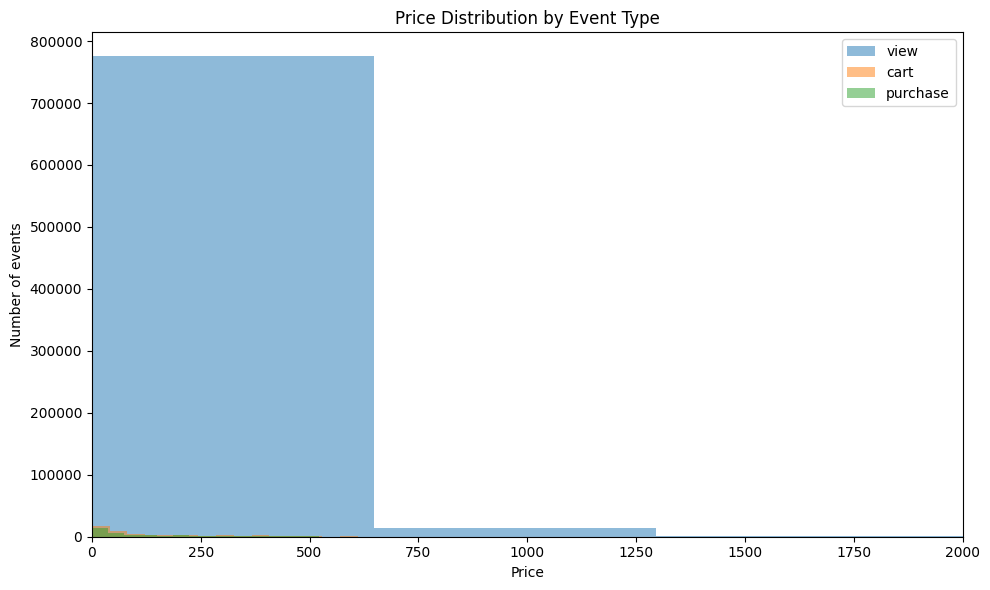

In [70]:
plt.figure(figsize=(10, 6))

for event in ['view', 'cart', 'purchase']:
    data = df_sessions.loc[
        df_sessions['event_type'] == event,
        'price'
    ]

    plt.hist(
        data,
        bins=100,
        alpha=0.5,
        label=event
    )

plt.xlim(0, 2000)

plt.xlabel('Price')
plt.ylabel('Number of events')
plt.title('Price Distribution by Event Type')
plt.legend()

plt.tight_layout()
plt.show()

### Интерпретация
На scatter plot особенно интересна зона:

**High Traffic + Below Benchmark**

Товары в этой области получают большое количество просмотров, но имеют конверсию View → Cart ниже среднего уровня.

Такие товары могут представлять потенциальные точки роста.

Важно отметить, что низкая конверсия сама по себе не означает наличие проблемы с товаром. Причины могут быть связаны с ценой, категорией, брендом, характеристиками товара или пользовательским спросом.

Поэтому данные товары следует рассматривать как кандидатов для дальнейшего исследования и A/B-тестирования.

In [71]:
overall_vtc = strict_view_to_cart

price_funnel['conversion_index'] = (
    price_funnel['view_to_cart'] /
    overall_vtc
)

price_funnel

event_type,price_band,view,cart,purchase,view_to_cart,cart_to_purchase,view_to_purchase,conversion_index
0,< $25,139367,9205,5947,0.066049,0.646062,0.042672,0.782426
1,$25–50,100981,7732,4995,0.076569,0.646017,0.049465,0.907051
2,$50–100,103532,7303,4206,0.070539,0.575928,0.040625,0.835615
3,$100–200,77855,6332,3604,0.081331,0.569172,0.046291,0.963460
4,$200–500,87241,11148,5655,0.127784,0.507266,0.064820,1.513756
5,$500–1K,19267,1989,1031,0.103234,0.518351,0.053511,1.222926
6,$1K–2.5K,4180,112,51,0.026794,0.455357,0.012201,0.317410
7,$2.5K+,790,22,7,0.027848,0.318182,0.008861,0.329894


In [72]:
price_funnel[
    [
        'price_band',
        'view',
        'cart',
        'purchase',
        'view_to_cart',
        'cart_to_purchase',
        'view_to_purchase',
        'conversion_index'
    ]
]

event_type,price_band,view,cart,purchase,view_to_cart,cart_to_purchase,view_to_purchase,conversion_index
0,< $25,139367,9205,5947,0.066049,0.646062,0.042672,0.782426
1,$25–50,100981,7732,4995,0.076569,0.646017,0.049465,0.907051
2,$50–100,103532,7303,4206,0.070539,0.575928,0.040625,0.835615
3,$100–200,77855,6332,3604,0.081331,0.569172,0.046291,0.963460
4,$200–500,87241,11148,5655,0.127784,0.507266,0.064820,1.513756
5,$500–1K,19267,1989,1031,0.103234,0.518351,0.053511,1.222926
6,$1K–2.5K,4180,112,51,0.026794,0.455357,0.012201,0.317410
7,$2.5K+,790,22,7,0.027848,0.318182,0.008861,0.329894


In [73]:
category_price_mix = (
    df_sessions[df_sessions['event_type'] == 'view']
    .groupby(['price_band', 'category_code'])['user_session']
    .nunique()
    .reset_index(name='view_sessions')
)

category_price_mix = category_price_mix.sort_values(
    ['price_band', 'view_sessions'],
    ascending=[True, False]
)

category_price_mix.head(20)

/var/folders/gv/gmp52n5x5zj2ybgm_gblbt1w0000gn/T/ipykernel_66650/4135257246.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['price_band', 'category_code'])['user_session']


,price_band,category_code,view_sessions
0,< $25,Unknown,64460
89,< $25,electronics.telephone,20406
105,< $25,stationery.cartrige,7688
52,< $25,computers.notebook,6771
59,< $25,computers.peripherals.printer,6327
88,< $25,electronics.tablet,4719
39,< $25,computers.components.cooler,3975
78,< $25,electronics.audio.acoustic,3507
80,< $25,electronics.audio.headphone,2535
97,< $25,furniture.living_room.shelving,1510


In [74]:
for band in price_labels:
    print(f"\n===== {band} =====")
    
    display(
        category_price_mix[
            category_price_mix['price_band'] == band
        ].head(5)
    )


===== < $25 =====


,price_band,category_code,view_sessions
0,< $25,Unknown,64460
89,< $25,electronics.telephone,20406
105,< $25,stationery.cartrige,7688
52,< $25,computers.notebook,6771
59,< $25,computers.peripherals.printer,6327



===== $25–50 =====


,price_band,category_code,view_sessions
108,$25–50,Unknown,33966
197,$25–50,electronics.telephone,15771
213,$25–50,stationery.cartrige,9925
160,$25–50,computers.notebook,6532
186,$25–50,electronics.audio.acoustic,3350



===== $50–100 =====


,price_band,category_code,view_sessions
216,$50–100,Unknown,27524
258,$50–100,computers.components.motherboard,9799
305,$50–100,electronics.telephone,7401
256,$50–100,computers.components.cpu,4263
294,$50–100,electronics.audio.acoustic,3866


... (6 outputs left out)


===== $1K–2.5K =====


,price_band,category_code,view_sessions
739,$1K–2.5K,electronics.video.tv,1013
648,$1K–2.5K,Unknown,660
737,$1K–2.5K,electronics.telephone,570
695,$1K–2.5K,computers.components.videocards,383
707,$1K–2.5K,computers.peripherals.printer,363



===== $2.5K+ =====


,price_band,category_code,view_sessions
808,$2.5K+,computers.notebook,209
756,$2.5K+,Unknown,171
847,$2.5K+,electronics.video.tv,143
815,$2.5K+,computers.peripherals.printer,99
812,$2.5K+,computers.peripherals.monitor,55


In [75]:
product_funnel = (
    df_sessions
    .groupby(['product_id', 'event_type'])['user_session']
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=['view', 'cart', 'purchase'], fill_value=0)
    .reset_index()
)

In [76]:
product_funnel['view_to_cart'] = (
    product_funnel['cart'] /
    product_funnel['view'].replace(0, pd.NA)
)

product_funnel['cart_to_purchase'] = (
    product_funnel['purchase'] /
    product_funnel['cart'].replace(0, pd.NA)
)

product_funnel['view_to_purchase'] = (
    product_funnel['purchase'] /
    product_funnel['view'].replace(0, pd.NA)
)

In [77]:
product_funnel_filtered = product_funnel[
    product_funnel['view'] >= 100
].copy()

print(f"Products before filter: {len(product_funnel):,}")
print(f"Products after filter: {len(product_funnel_filtered):,}")

Products before filter: 53,452
Products after filter: 908


In [78]:
top_products = (
    product_funnel_filtered
    .sort_values('view', ascending=False)
    .head(20)
)

top_products

event_type,product_id,view,cart,purchase,view_to_cart,cart_to_purchase,view_to_purchase
40709,1821813,9527,1140,447,0.11966,0.392105,0.046919
46705,3791351,3895,671,284,0.172272,0.423249,0.072914
39578,1785245,3745,253,152,0.067557,0.600791,0.040587
50559,4099645,3527,912,424,0.258577,0.464912,0.120215
47812,3829355,3386,578,392,0.170703,0.678201,0.115771
19187,809948,2818,248,137,0.088006,0.552419,0.048616
41011,1830099,2797,353,145,0.126207,0.410765,0.051841
46769,3791509,2348,299,119,0.127342,0.397993,0.050681
47424,3828501,1933,120,64,0.06208,0.533333,0.033109
23539,893196,1895,580,292,0.306069,0.503448,0.15409


In [79]:
product_funnel_filtered['expected_carts'] = (
    product_funnel_filtered['view'] *
    overall_vtc
)

product_funnel_filtered['cart_gap'] = (
    product_funnel_filtered['expected_carts'] -
    product_funnel_filtered['cart']
)

In [80]:
product_opportunities = (
    product_funnel_filtered
    .sort_values('cart_gap', ascending=False)
    .head(20)
)

product_opportunities[
    [
        'product_id',
        'view',
        'cart',
        'purchase',
        'view_to_cart',
        'view_to_purchase',
        'cart_gap'
    ]
]

event_type,product_id,view,cart,purchase,view_to_cart,view_to_purchase,cart_gap
17884,775032,909,0,0,0.0,0.0,76.733404
37115,1674260,806,0,0,0.0,0.0,68.038640
8172,387956,1153,31,9,0.026886,0.007806,66.330709
3379,229036,892,9,0,0.01009,0.0,66.298345
39578,1785245,3745,253,152,0.067557,0.040587,63.134870
12189,589968,723,0,0,0.0,0.0,61.032179
1068,83737,714,1,0,0.001401,0.0,59.272442
52816,4163312,810,12,2,0.014815,0.002469,56.376300
15912,698803,568,1,0,0.001761,0.0,46.947825
47424,3828501,1933,120,64,0.06208,0.033109,43.174554


In [81]:
category_price_mix

,price_band,category_code,view_sessions
0,< $25,Unknown,64460
89,< $25,electronics.telephone,20406
105,< $25,stationery.cartrige,7688
52,< $25,computers.notebook,6771
59,< $25,computers.peripherals.printer,6327
...,...,...,...
859,$2.5K+,sport.bicycle,0
860,$2.5K+,stationery.battery,0
861,$2.5K+,stationery.cartrige,0
862,$2.5K+,stationery.paper,0


In [82]:
product_opportunities

event_type,product_id,view,cart,purchase,view_to_cart,cart_to_purchase,view_to_purchase,expected_carts,cart_gap
17884,775032,909,0,0,0.0,<NA>,0.0,76.733404,76.733404
37115,1674260,806,0,0,0.0,<NA>,0.0,68.038640,68.038640
8172,387956,1153,31,9,0.026886,0.290323,0.007806,97.330709,66.330709
3379,229036,892,9,0,0.01009,0.0,0.0,75.298345,66.298345
39578,1785245,3745,253,152,0.067557,0.600791,0.040587,316.134870,63.134870
12189,589968,723,0,0,0.0,<NA>,0.0,61.032179,61.032179
1068,83737,714,1,0,0.001401,0.0,0.0,60.272442,59.272442
52816,4163312,810,12,2,0.014815,0.166667,0.002469,68.376300,56.376300
15912,698803,568,1,0,0.001761,0.0,0.0,47.947825,46.947825
47424,3828501,1933,120,64,0.06208,0.533333,0.033109,163.174554,43.174554


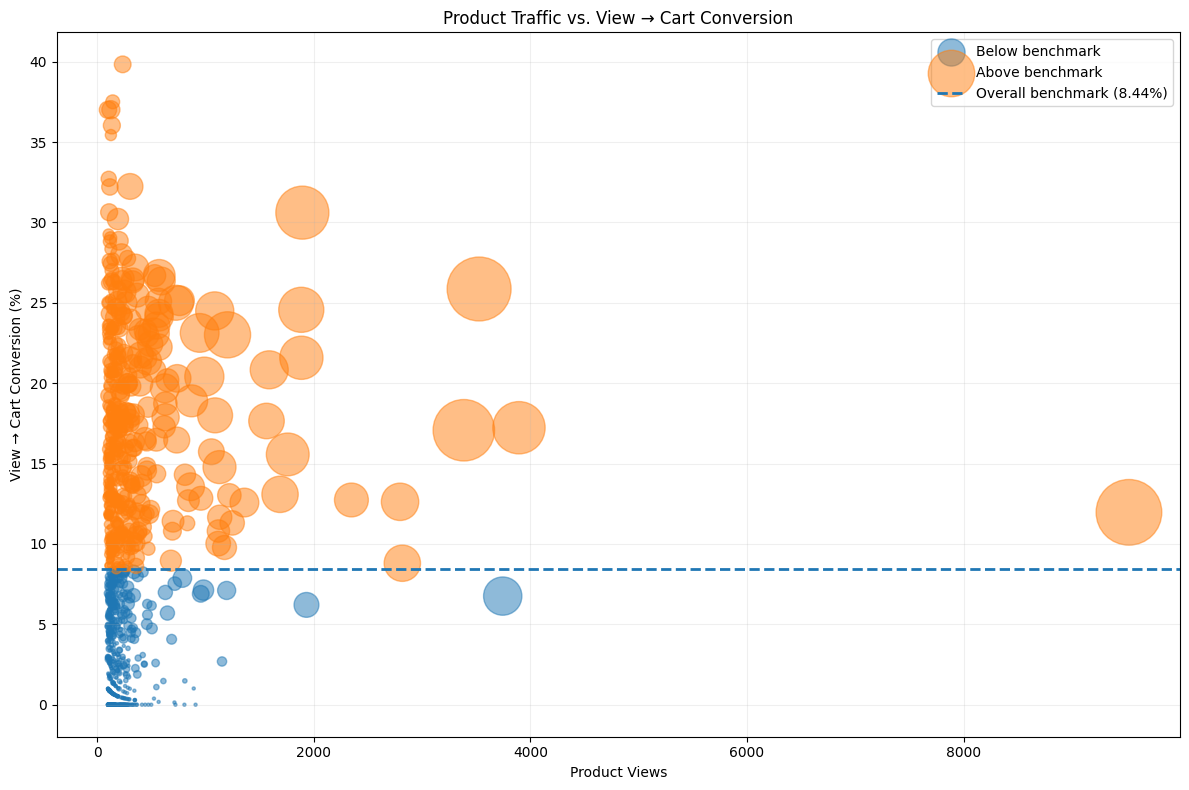

In [83]:
import numpy as np
plot_products = product_funnel_filtered.copy()

# Классификация относительно benchmark
plot_products['performance'] = np.where(
    plot_products['view_to_cart'] >= overall_vtc,
    'Above benchmark',
    'Below benchmark'
)

# Scatter plot
plt.figure(figsize=(12, 8))

for performance in ['Below benchmark', 'Above benchmark']:
    data = plot_products[
        plot_products['performance'] == performance
    ]

    plt.scatter(
        data['view'],
        data['view_to_cart'] * 100,
        s=data['purchase'].clip(lower=1) * 5,
        alpha=0.5,
        label=performance
    )

# Benchmark line
plt.axhline(
    overall_vtc * 100,
    linestyle='--',
    linewidth=2,
    label=f'Overall benchmark ({overall_vtc:.2%})'
)

plt.xlabel('Product Views')
plt.ylabel('View → Cart Conversion (%)')
plt.title('Product Traffic vs. View → Cart Conversion')

plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

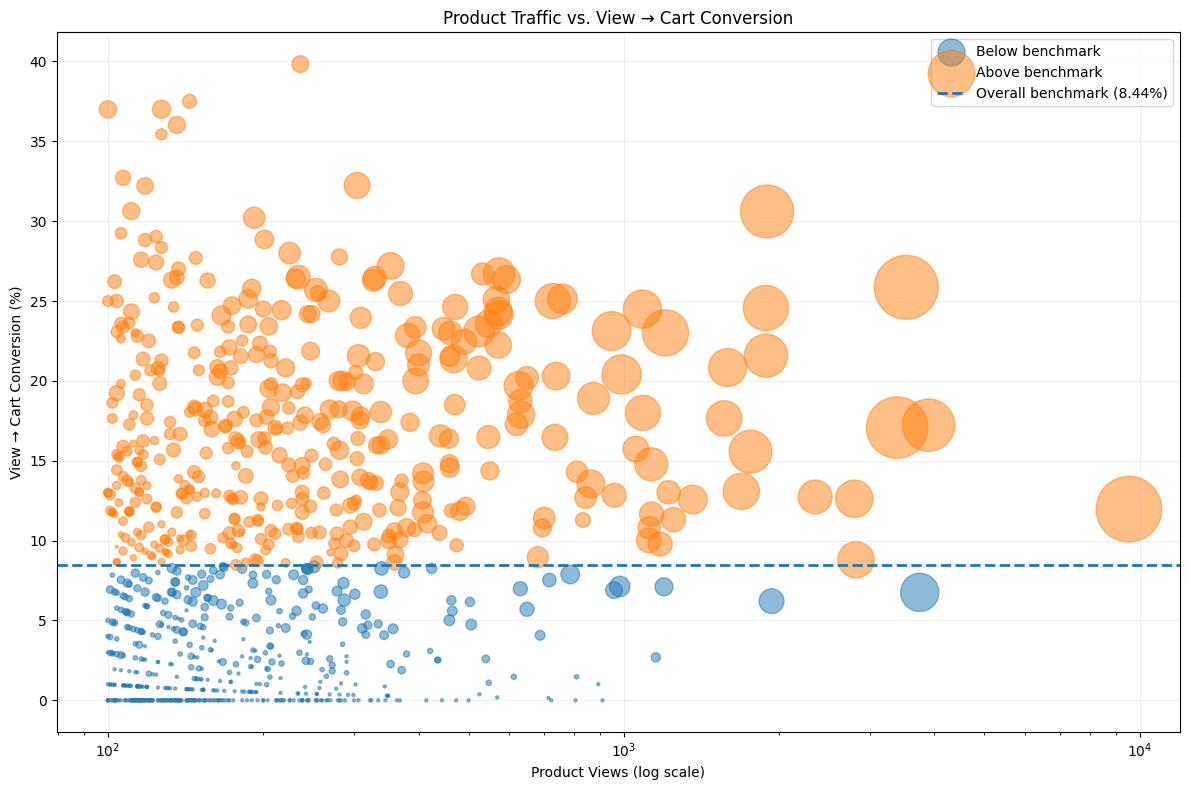

In [84]:
plt.figure(figsize=(12, 8))

for performance in ['Below benchmark', 'Above benchmark']:
    data = plot_products[
        plot_products['performance'] == performance
    ]

    plt.scatter(
        data['view'],
        data['view_to_cart'] * 100,
        s=data['purchase'].clip(lower=1) * 5,
        alpha=0.5,
        label=performance
    )

plt.axhline(
    overall_vtc * 100,
    linestyle='--',
    linewidth=2,
    label=f'Overall benchmark ({overall_vtc:.2%})'
)

plt.xscale('log')

plt.xlabel('Product Views (log scale)')
plt.ylabel('View → Cart Conversion (%)')
plt.title('Product Traffic vs. View → Cart Conversion')

plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [85]:
opportunity_products = (
    product_funnel_filtered[
        product_funnel_filtered['view_to_cart'] < overall_vtc
    ]
    .sort_values('cart_gap', ascending=False)
    .head(10)
    .copy()
)

opportunity_products[
    [
        'product_id',
        'view',
        'cart',
        'purchase',
        'view_to_cart',
        'view_to_purchase',
        'expected_carts',
        'cart_gap'
    ]
]

event_type,product_id,view,cart,purchase,view_to_cart,view_to_purchase,expected_carts,cart_gap
17884,775032,909,0,0,0.0,0.0,76.733404,76.733404
37115,1674260,806,0,0,0.0,0.0,68.038640,68.038640
8172,387956,1153,31,9,0.026886,0.007806,97.330709,66.330709
3379,229036,892,9,0,0.01009,0.0,75.298345,66.298345
39578,1785245,3745,253,152,0.067557,0.040587,316.134870,63.134870
12189,589968,723,0,0,0.0,0.0,61.032179,61.032179
1068,83737,714,1,0,0.001401,0.0,60.272442,59.272442
52816,4163312,810,12,2,0.014815,0.002469,68.376300,56.376300
15912,698803,568,1,0,0.001761,0.0,47.947825,46.947825
47424,3828501,1933,120,64,0.06208,0.033109,163.174554,43.174554


In [86]:
opportunity_table = opportunity_products[
    [
        'product_id',
        'view',
        'cart',
        'purchase',
        'view_to_cart',
        'view_to_purchase',
        'cart_gap'
    ]
].copy()

opportunity_table['view_to_cart'] = (
    opportunity_table['view_to_cart'] * 100
)

opportunity_table['view_to_purchase'] = (
    opportunity_table['view_to_purchase'] * 100
)

opportunity_table['cart_gap'] = (
    opportunity_table['cart_gap']
)

opportunity_table.columns = [
    'Product ID',
    'Views',
    'Cart Sessions',
    'Purchase Sessions',
    'View → Cart %',
    'View → Purchase %',
    'Benchmark Cart Gap'
]

opportunity_table

,Product ID,Views,Cart Sessions,Purchase Sessions,View → Cart %,View → Purchase %,Benchmark Cart Gap
17884,775032,909,0,0,0.0,0.0,76.733404
37115,1674260,806,0,0,0.0,0.0,68.038640
8172,387956,1153,31,9,2.688638,0.780572,66.330709
3379,229036,892,9,0,1.008969,0.0,66.298345
39578,1785245,3745,253,152,6.755674,4.058745,63.134870
12189,589968,723,0,0,0.0,0.0,61.032179
1068,83737,714,1,0,0.140056,0.0,59.272442
52816,4163312,810,12,2,1.481481,0.246914,56.376300
15912,698803,568,1,0,0.176056,0.0,46.947825
47424,3828501,1933,120,64,6.207967,3.310916,43.174554


## Opportunity Products
На основе benchmark были выделены товары с наибольшим потенциальным conversion gap.

Показатель Benchmark Cart Gap представляет собой оценочную разницу между фактическим количеством Cart Sessions и количеством сессий, которое наблюдалось бы при достижении общего benchmark View → Cart (8,44%).

Это не прогноз дополнительного количества заказов, а аналитический показатель для приоритизации товаров.

In [87]:
high_performing_products = (
    product_funnel_filtered[
        product_funnel_filtered['view_to_cart'] >= overall_vtc
    ]
    .sort_values(
        ['view', 'view_to_cart'],
        ascending=[False, False]
    )
    .head(10)
    .copy()
)

high_performing_products[
    [
        'product_id',
        'view',
        'cart',
        'purchase',
        'view_to_cart',
        'view_to_purchase'
    ]
]

event_type,product_id,view,cart,purchase,view_to_cart,view_to_purchase
40709,1821813,9527,1140,447,0.11966,0.046919
46705,3791351,3895,671,284,0.172272,0.072914
50559,4099645,3527,912,424,0.258577,0.120215
47812,3829355,3386,578,392,0.170703,0.115771
19187,809948,2818,248,137,0.088006,0.048616
41011,1830099,2797,353,145,0.126207,0.051841
46769,3791509,2348,299,119,0.127342,0.050681
23539,893196,1895,580,292,0.306069,0.15409
52056,4154414,1886,407,194,0.215801,0.102863
51769,4102739,1885,463,211,0.245623,0.111936


In [88]:
purchase_df = df_sessions[
    df_sessions['event_type'] == 'purchase'
].copy()

gmv = purchase_df['price'].sum()

print(f"Observed GMV: ${gmv:,.2f}")

Observed GMV: $5,125,113.92


In [89]:
purchase_df['price'].agg([
    'count',
    'mean',
    'median',
    'min',
    'max'
])

count     37343.000000
mean        137.244301
median       64.480000
min           0.220000
max        3717.650000
Name: price, dtype: float64

In [90]:
gmv_by_price = (
    purchase_df
    .groupby('price_band', observed=True)
    .agg(
        purchases=('price', 'count'),
        gmv=('price', 'sum')
    )
    .reset_index()
)

gmv_by_price['gmv_share'] = (
    gmv_by_price['gmv'] /
    gmv_by_price['gmv'].sum()
)

gmv_by_price

,price_band,purchases,gmv,gmv_share
0,< $25,8755,132451.50,0.025844
1,$25–50,7218,251207.82,0.049015
2,$50–100,6429,453396.89,0.088466
3,$100–200,5355,766959.24,0.149647
4,$200–500,8165,2561827.32,0.499858
5,$500–1K,1355,855556.60,0.166934
6,$1K–2.5K,59,81429.26,0.015888
7,$2.5K+,7,22285.29,0.004348


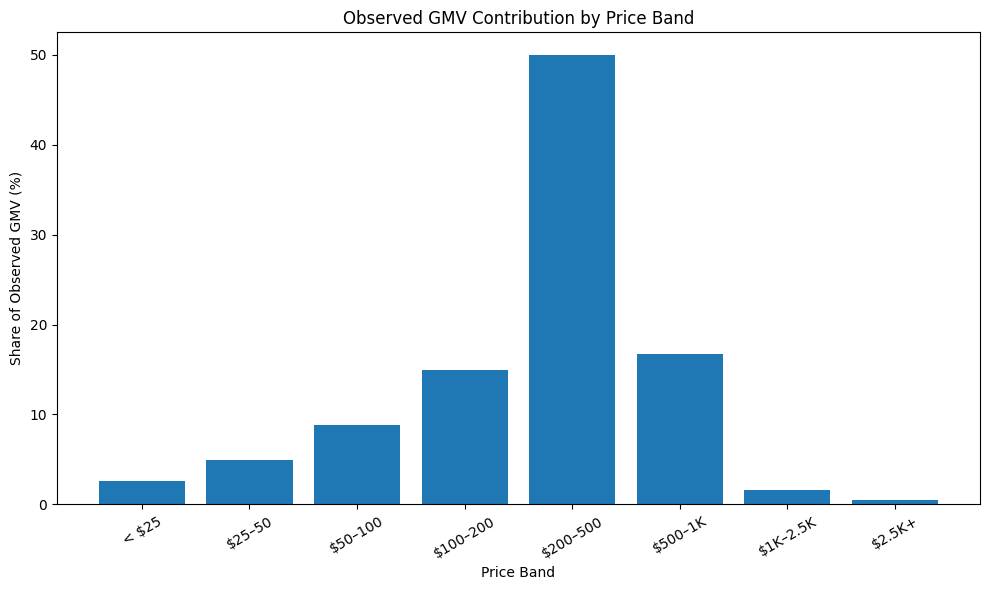

In [91]:
plt.figure(figsize=(10, 6))

plt.bar(
    gmv_by_price['price_band'].astype(str),
    gmv_by_price['gmv_share'] * 100
)

plt.xlabel('Price Band')
plt.ylabel('Share of Observed GMV (%)')
plt.title('Observed GMV Contribution by Price Band')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [92]:
gmv_by_price

,price_band,purchases,gmv,gmv_share
0,< $25,8755,132451.50,0.025844
1,$25–50,7218,251207.82,0.049015
2,$50–100,6429,453396.89,0.088466
3,$100–200,5355,766959.24,0.149647
4,$200–500,8165,2561827.32,0.499858
5,$500–1K,1355,855556.60,0.166934
6,$1K–2.5K,59,81429.26,0.015888
7,$2.5K+,7,22285.29,0.004348


In [93]:
views, carts, purchases = strict_funnel['View'], strict_funnel['Cart'], strict_funnel['Purchase']
ctp = purchases / carts  
avg_ticket = gmv / df_sessions.loc[df_sessions['is_purchase'], 'user_session'].nunique()

rows = []
for lift in [0.005, 0.01, 0.02]:
    extra = views * lift * ctp
    rows.append({
        'scenario': f'View→Cart +{lift*100:.1f} п.п.',
        'extra_purchases': extra,
        'purchase_growth_pct': extra / purchases * 100,
        'extra_gmv_usd': extra * avg_ticket,
    })

extra = carts * 0.01
rows.append({
    'scenario': 'Cart→Purchase +1.0 п.п.',
    'extra_purchases': extra,
    'purchase_growth_pct': extra / purchases * 100,
    'extra_gmv_usd': extra * avg_ticket,
})

scenario_table = pd.DataFrame(rows).round(1)
scenario_table

,scenario,extra_purchases,purchase_growth_pct,extra_gmv_usd
0,View→Cart +0.5 п.п.,1226.0,5.9,258100.8
1,View→Cart +1.0 п.п.,2451.9,11.8,516201.6
2,View→Cart +2.0 п.п.,4903.9,23.7,1032403.3
3,Cart→Purchase +1.0 п.п.,412.2,2.0,86790.5


## Вывод
Ценовой сегмент **$200–500** является ключевым с точки зрения transaction value.

На него приходится около **50% Observed GMV** в анализируемых данных.

При этом именно этот сегмент ранее продемонстрировал наиболее высокий показатель View → Cart — **12,78%.**

Таким образом, сегмент $200–500 сочетает:

высокий уровень вовлечения;
высокую конверсию в корзину;
значительную коммерческую ценность.
Это делает его наиболее интересным сегментом для дальнейшего анализа и оптимизации.

## 7. Анализ transaction value
Для оценки коммерческой значимости различных ценовых сегментов используется сумма цен по событиям purchase.

В рамках проекта показатель называется **Observed GMV.**

Он не интерпретируется как чистая выручка компании, поскольку в данных отсутствует информация о:

скидках;
возвратах;
налогах;
стоимости доставки;
количестве товаров в заказе;
фактической оплате.
Поэтому показатель используется исключительно для сравнительного анализа ценовых сегментов.

## 8. Ключевые выводы
### 1. Основная проблема воронки находится на этапе View → Cart

Только **8,44%** сессий с просмотром товара переходят к добавлению товара в корзину.

При этом **50,21%** сессий, дошедших до Cart после View, завершаются покупкой.

Сценарный расчёт подтверждает, что View → Cart — главный рычаг: +1 п.п. на этом этапе даёт около **+2 452 покупок (+11,8%)**, а +1 п.п. на этапе Cart → Purchase — около **+412 покупок (+2,0%)**. Допущение: дополнительные корзины конвертируются в покупку с текущей долей 50,21%; оценка GMV (≈$516 тыс. против ≈$87 тыс.) использует средний Observed GMV на сессию с покупкой.

Следовательно, основной потенциал улучшения находится на этапе формирования намерения купить.

### 2. Сегмент $200–500 демонстрирует лучшую конверсию

View → Cart для товаров стоимостью $200–500 составляет **12,78%**, что примерно на 51% выше общего benchmark.

Этот ценовой сегмент является наиболее эффективным по переходу от просмотра к корзине.

### 3. Сегмент $200–500 также является главным источником transaction value

На товары стоимостью $200–500 приходится около **50% Observed GMV.**

Это делает данный сегмент особенно важным с точки зрения бизнеса.

### 4. Очень дорогие товары конвертируют значительно хуже

Для товаров стоимостью выше $1 000 View → Cart Conversion опускается примерно до **2,7–2,8%** ($1K–2.5K: 2,68%; $2.5K+: 2,78%).

Это существенно ниже общего benchmark 8,44%.

Выборка в этих сегментах небольшая ($2.5K+: 790 сессий с просмотром, 22 с корзиной, 7 покупок). Максимальная цена в данных ($64 771) — цена одной позиции без единой покупки, а не стоимость корзины.

Возможные причины требуют дополнительного исследования и не могут быть определены только на основе данного анализа.

### 5. Некоторые высокотрафиковые товары имеют conversion ниже benchmark

Анализ Traffic × Conversion позволил выделить товары с большим количеством просмотров и относительно низкой конверсией.

Такие товары являются потенциальными кандидатами для дальнейшего исследования:

- сравнение цен;
- анализ карточек товара;
- изучение отзывов;
- проверка наличия;
- исследование конкурентных предложений;
- проведение A/B-тестов.

### 6. Качество данных: товары без категории

Категория не указана у **26,7% событий** и **35,3% товаров**. Такие записи помечены как `Unknown` и исключены из анализа категорий (остаётся 648 311 событий и 107 категорий). В таблице `funnel_by_category` для Power BI они сохранены с флагом `is_categorized = False`.

## 9. Бизнес-рекомендации
### 1. Оптимизировать этап View → Cart

Основное внимание следует направить на повышение перехода от просмотра товара к добавлению в корзину: +1 п.п. на этом этапе даёт около +11,8% покупок, тогда как +1 п.п. на Cart → Purchase — около +2,0%.

### 2. Отдельно исследовать сегмент $200–500

Этот сегмент показывает одновременно высокую конверсию и высокую коммерческую значимость.

### 3. Провести дополнительный анализ товаров с высоким трафиком и низкой конверсией

Такие товары могут дать наибольший потенциальный эффект при улучшении conversion rate.

### 4. Отдельно исследовать товары стоимостью $1 000+

Необходимо понять, связано ли снижение конверсии с ценой или с особенностями категорий и ассортимента. Выборка небольшая (в сегменте $2.5K+ только 790 сессий с просмотром и 7 покупок), поэтому выводы предварительные.

### 5. Использовать A/B-тестирование для проверки гипотез

Наблюдаемые зависимости следует рассматривать как гипотезы. Их влияние на бизнес-метрики необходимо подтверждать экспериментально.

## 10. Заключение
Проведённый анализ позволил определить основные точки потерь в пользовательской воронке интернет-магазина и выявить наиболее перспективные направления для дальнейшей оптимизации.

Главный результат исследования — основной drop-off происходит между просмотром товара и добавлением его в корзину.

Наиболее интересным сегментом оказался диапазон $200–500, который одновременно демонстрирует высокую View → Cart Conversion и формирует около половины Observed GMV.

Дополнительный анализ товаров позволил выделить высокотрафиковые позиции с конверсией ниже benchmark, которые могут стать приоритетными объектами для дальнейшего исследования.

Следующим практическим шагом может стать проверка сформированных гипотез с помощью A/B-тестов и более детального анализа категорий, брендов и пользовательских сегментов.

## 11. Подготовка данных для Power BI

Для визуализации результатов анализа в Power BI создаётся отдельный набор таблиц.

Модель данных разделяется на:

таблицу событий;
справочник товаров;
календарь;
таблицу товарных возможностей.
Такой подход позволяет отделить подготовку данных от визуального анализа и использовать единый набор метрик в dashboard.

**Примечание по категориям.** Товары без категории (26,7% событий, 35,3% товаров) хранятся как `Unknown`. В `dim_product` для каждого товара берётся запись с известной категорией и брендом, если такая есть. В анализе категорий они исключены, поэтому benchmark View → Cart по категориям (**10,12%**, 54 категории с ≥1 000 просмотров) отличается от общего benchmark воронки (**8,44%**): первый считается только по сессиям с известной категорией. В `funnel_by_category` добавлен флаг `is_categorized` для фильтрации в Power BI.

In [94]:
fact_events = df.copy()

fact_events['event_datetime'] = pd.to_datetime(fact_events['event_time'], utc=True)
fact_events['event_date'] = fact_events['event_datetime'].dt.date
fact_events['event_hour'] = fact_events['event_datetime'].dt.hour
fact_events['day_of_week'] = fact_events['event_datetime'].dt.day_name()

fact_events['event_datetime'] = fact_events['event_datetime'].dt.tz_localize(None)

price_bins = [0, 25, 50, 100, 200, 500, 1000, 2500, float('inf')]
price_labels = ['< $25', '$25–50', '$50–100', '$100–200',
                '$200–500', '$500–1K', '$1K–2.5K', '$2.5K+']

fact_events['price_band'] = pd.cut(
    fact_events['price'], bins=price_bins, labels=price_labels, include_lowest=True
)

fact_events = fact_events[[
    'event_datetime', 'event_date', 'event_hour', 'day_of_week',
    'event_type', 'user_id', 'user_session',
    'product_id', 'category_id', 'category_code', 'brand',
    'price', 'price_band'
]].copy()

fact_events.head()

,event_datetime,event_date,event_hour,day_of_week,event_type,user_id,user_session,product_id,category_id,category_code,brand,price,price_band
0,2020-09-24 11:57:06,2020-09-24,11,Thursday,view,1515915625519388267,LJuJVLEjPT,1996170,2144415922528452715,electronics.telephone,Unknown,31.90,$25–50
1,2020-09-24 11:57:26,2020-09-24,11,Thursday,view,1515915625519380411,tdicluNnRY,139905,2144415926932472027,computers.components.cooler,zalman,17.16,< $25
2,2020-09-24 11:57:27,2020-09-24,11,Thursday,view,1515915625513238515,4TMArHtXQy,215454,2144415927158964449,Unknown,Unknown,9.81,< $25
3,2020-09-24 11:57:33,2020-09-24,11,Thursday,view,1515915625519014356,aGFYrNgC08,635807,2144415923107266682,computers.peripherals.printer,pantum,113.81,$100–200
4,2020-09-24 11:57:36,2020-09-24,11,Thursday,view,1515915625510743344,aa4mmk0kwQ,3658723,2144415921169498184,Unknown,cameronsino,15.87,< $25


In [95]:
print(fact_events.shape)

print("\nColumns:")
print(fact_events.columns.tolist())

print("\nPrice bands:")
print(fact_events['price_band'].value_counts().sort_index())

(884474, 13)

Columns:
['event_datetime', 'event_date', 'event_hour', 'day_of_week', 'event_type', 'user_id', 'user_session', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'price_band']

Price bands:
price_band
< $25       210810
$25–50      156891
$50–100     171964
$100–200    131925
$200–500    172483
$500–1K      33946
$1K–2.5K      5460
$2.5K+         995
Name: count, dtype: int64


In [96]:
dim_product = (
    fact_events[['product_id', 'category_id', 'category_code', 'brand']]
    .assign(_unknowns=lambda d: (d['category_code'] == 'Unknown').astype(int)
                              + (d['brand'] == 'Unknown').astype(int))
    .sort_values('_unknowns')          # rows with known category/brand come first
    .drop_duplicates('product_id')
    .drop(columns='_unknowns')
    .reset_index(drop=True)
)

parts = dim_product['category_code'].str.split('.', expand=True)
dim_product['category_l1'] = parts[0]
dim_product['category_l2'] = (parts[1] if 1 in parts.columns else None)
dim_product['category_l2'] = dim_product['category_l2'].fillna('Unknown')

print(f"Products: {len(dim_product):,}")
print(f"Unknown category: {(dim_product['category_code'] == 'Unknown').mean():.1%} of products")
dim_product.head()

Products: 53,453
Unknown category: 35.3% of products


,product_id,category_id,category_code,brand,category_l1,category_l2
0,4101537,2144415922427789416,computers.components.videocards,asus,computers,components
1,33165,2144415925430911157,appliances.kitchen.coffee_machine,delonghi,appliances,kitchen
2,138446,2144415926890528986,computers.components.sound_card,creative,computers,components
3,4155052,2144415922427789416,computers.components.videocards,gigabyte,computers,components
4,933650,2144415922092245087,computers.peripherals.joystick,logitech,computers,peripherals


In [97]:
date_range = pd.date_range(
    start=fact_events['event_datetime'].min().normalize(),
    end=fact_events['event_datetime'].max().normalize(),
    freq='D'
)

dim_date = pd.DataFrame({'Date': date_range})
dim_date['Year'] = dim_date['Date'].dt.year
dim_date['Month'] = dim_date['Date'].dt.month
dim_date['Month Name'] = dim_date['Date'].dt.strftime('%b')
dim_date['Year Month'] = dim_date['Date'].dt.strftime('%Y-%m')
dim_date['Week'] = dim_date['Date'].dt.isocalendar().week.astype(int)
dim_date['Day of Week'] = dim_date['Date'].dt.day_name()
dim_date['Date'] = dim_date['Date'].dt.date

dim_date.head()

,Date,Year,Month,Month Name,Year Month,Week,Day of Week
0,2020-09-24,2020,9,Sep,2020-09,39,Thursday
1,2020-09-25,2020,9,Sep,2020-09,39,Friday
2,2020-09-26,2020,9,Sep,2020-09,39,Saturday
3,2020-09-27,2020,9,Sep,2020-09,39,Sunday
4,2020-09-28,2020,9,Sep,2020-09,40,Monday


In [98]:
product_opportunities = product_funnel_filtered.copy()

product_opportunities['performance'] = np.where(
    product_opportunities['view_to_cart'] >= overall_vtc,
    'Above benchmark',
    'Below benchmark'
)

product_opportunities = product_opportunities[
    [
        'product_id',
        'view',
        'cart',
        'purchase',
        'view_to_cart',
        'view_to_purchase',
        'cart_gap',
        'performance'
    ]
].copy()

product_opportunities.columns = [
    'product_id',
    'views',
    'cart_sessions',
    'purchase_sessions',
    'view_to_cart',
    'view_to_purchase',
    'benchmark_cart_gap',
    'performance'
]

print(f"Products in opportunity table: {len(product_opportunities):,}")

product_opportunities.head()

Products in opportunity table: 908


,product_id,views,cart_sessions,purchase_sessions,view_to_cart,view_to_purchase,benchmark_cart_gap,performance
1,105,612,9,3,0.014706,0.004902,42.662094,Below benchmark
42,2260,202,6,2,0.029703,0.009901,11.051867,Below benchmark
50,2712,178,17,10,0.095506,0.05618,-1.974097,Above benchmark
51,2717,506,24,12,0.047431,0.023715,18.714084,Below benchmark
54,2855,272,5,4,0.018382,0.014706,17.960930,Below benchmark


In [99]:
print("fact_events:", fact_events.shape)
print("dim_product:", dim_product.shape)
print("dim_date:", dim_date.shape)
print("product_opportunities:", product_opportunities.shape)

fact_events: (884474, 13)
dim_product: (53453, 6)
dim_date: (158, 7)
product_opportunities: (908, 8)


In [100]:
print("\nMissing values:")

print("\nfact_events")
print(fact_events.isna().sum())

print("\ndim_product")
print(dim_product.isna().sum())

print("\ndim_date")
print(dim_date.isna().sum())

print("\nproduct_opportunities")
print(product_opportunities.isna().sum())


Missing values:

fact_events
event_datetime      0
event_date          0
event_hour          0
day_of_week         0
event_type          0
user_id             0
user_session      162
product_id          0
category_id         0
category_code       0
brand               0
price               0
price_band          0
dtype: int64

dim_product
product_id       0
category_id      0
category_code    0
brand            0
category_l1      0
category_l2      0
dtype: int64

dim_date
Date           0
Year           0
Month          0
Month Name     0
Year Month     0
Week           0
Day of Week    0
dtype: int64

product_opportunities
product_id            0
views                 0
cart_sessions         0
purchase_sessions     0
view_to_cart          0
view_to_purchase      0
benchmark_cart_gap    0
performance           0
dtype: int64


In [101]:
fact_sessions = (
    df_sessions.groupby('user_session')
    .agg(
        user_id=('user_id', 'first'),
        session_date=('event_datetime', lambda x: x.min().date()),
        has_view=('is_view', 'max'),
        has_valid_cart=('valid_cart', 'max'),
        has_valid_purchase=('valid_purchase', 'max'),
        has_any_purchase=('is_purchase', 'max'),
        events=('event_type', 'size'),
    )
    .reset_index()
)

flag_cols = ['has_view', 'has_valid_cart', 'has_valid_purchase', 'has_any_purchase']
fact_sessions[flag_cols] = fact_sessions[flag_cols].astype(int)

fact_sessions.head()

,user_session,user_id,session_date,has_view,has_valid_cart,has_valid_purchase,has_any_purchase,events
0,000AMhYaQu,1515915625599214495,2021-01-31,1,0,0,0,1
1,000c34fa-991f-442a-8e07-8c472269bec6,1515915625509232600,2020-09-30,1,0,0,0,1
2,001HttdHUk,1515915625591270059,2021-01-09,1,0,0,0,1
3,001P7lK0Pt,1515915625536141302,2020-11-06,1,0,0,0,2
4,001RxUtFJa,1515915625570256322,2020-12-29,1,0,0,0,1


In [102]:
df_sessions['session_date'] = df_sessions['user_session'].map(
    fact_sessions.set_index('user_session')['session_date']
)

def strict_funnel_by(col):
    g = (
        df_sessions
        .groupby(['session_date', col, 'user_session'], observed=True)
        .agg(v=('is_view', 'max'),
             c=('valid_cart', 'max'),
             p=('valid_purchase', 'max'))
        .reset_index()
    )
    return (
        g.groupby(['session_date', col], observed=True)
         .agg(view_sessions=('v', 'sum'),
              cart_sessions=('c', 'sum'),
              purchase_sessions=('p', 'sum'))
         .reset_index()
    )

funnel_by_price_band = strict_funnel_by('price_band')
funnel_by_category = strict_funnel_by('category_code')
funnel_by_category['is_categorized'] = funnel_by_category['category_code'].ne('Unknown')

dim_price_band = pd.DataFrame({
    'price_band': price_labels,
    'sort_order': range(1, len(price_labels) + 1)
})

print(funnel_by_price_band.shape, funnel_by_category.shape)

(1263, 5) (13622, 6)


In [103]:
tables = {
    'fact_events': fact_events,
    'fact_sessions': fact_sessions,
    'dim_product': dim_product,
    'dim_date': dim_date,
    'dim_price_band': dim_price_band,
    'product_opportunities': product_opportunities,
    'funnel_by_price_band': funnel_by_price_band,
    'funnel_by_category': funnel_by_category,
}

for name, frame in tables.items():
    frame.to_csv(f'{name}.csv', index=False)

print("Power BI files created successfully.")

Power BI files created successfully.


In [104]:
import os

for name in tables:
    size_mb = os.path.getsize(f'{name}.csv') / (1024 ** 2)
    print(f"{name}.csv: {size_mb:.2f} MB")

fact_events.csv: 126.48 MB
fact_sessions.csv: 24.40 MB
dim_product.csv: 3.69 MB
dim_date.csv: 0.01 MB
dim_price_band.csv: 0.00 MB
product_opportunities.csv: 0.07 MB
funnel_by_price_band.csv: 0.04 MB
funnel_by_category.csv: 0.63 MB


In [105]:
print(fact_sessions[['has_view', 'has_valid_cart', 'has_valid_purchase']].sum())
# ожидается: 488360 / 41225 / 20698

has_view              488360
has_valid_cart         41225
has_valid_purchase     20698
dtype: int64
